# Chapter 02: Data and Sampling Distributions

**Primary Reference:**

Peter Bruce, Andrew Bruce, and Peter Gedeck,  
*Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python (2nd Edition)*  
O'Reilly Media

## 1. Chapter Summary

**Data and sampling distributions** are fundamental concepts in statistical analysis that focus on **understanding how samples represent populations and how statistical estimates vary across repeated sampling processes**.

This chapter examines random sampling, sample bias, selection bias, regression to the mean, sampling distributions, the central limit theorem, standard error, bootstrap resampling, and confidence intervals.

Probability distributions including normal, Student’s t, binomial, chi‑square, F, Poisson, exponential, and Weibull are discussed, with Python implementations illustrating practical applications in real‑world data analysis.


## 2. Learning Objectives

This chapter aims to provide an understanding of:

- Explaining principles of random sampling and addressing sample bias.
- Analyzing causes of selection bias and describing regression to the mean.
- Understanding sampling distributions, applying the central limit theorem, and interpreting standard error.
- Applying bootstrap resampling for estimating variability and uncertainty.
- Constructing and interpreting confidence intervals using statistical methods.
- Conducting normal distribution analysis with z‑scores and Q‑Q plots.
- Examining long‑tailed distributions and evaluating implications for extreme values.
- Utilizing Student’s t‑distribution for estimating means with unknown variance.
- Applying binomial distribution for calculating probabilities in binary trials.
- Using chi‑square distribution for analyzing categorical data.
- Employing F‑distribution for variance comparisons and model evaluation.
- Modeling event counts, waiting times, and failure data with Poisson, exponential, and Weibull distributions.

## 3. Theoretical Explanation & Implementation

This section presents the theoretical concepts and practical implementations discussed in Chapter 2 through conceptual explanations, mathematical representations, dataset sources, code reproduction, additional demonstrations, and analytical interpretations.

### 3.1 Random Sampling and Sample Bias

#### 3.1.1 Concept Explanation

#### Mathematical Representation

#### 3.1.2 Code Reproduction

,Population (%),Random Sample (%),Convenience Sample (%)
Segment,,,
A,69.5,72.5,100.0
B,20.2,17.2,0.0
C,10.3,10.2,0.0


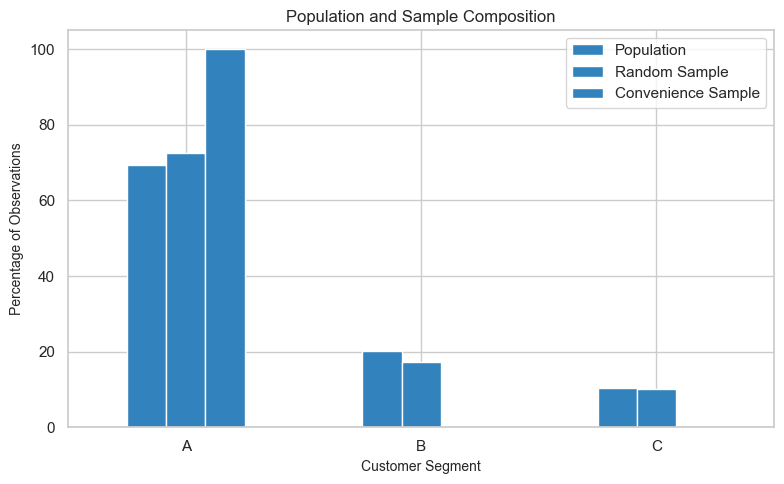

In [2]:
rng = np.random.default_rng(101)

population_size = 10000

population = pd.DataFrame({
    "Segment": rng.choice(
        ["A", "B", "C"],
        size=population_size,
        p=[0.70, 0.20, 0.10]
    )
})

population["MonthlySpend"] = np.select(
    [
        population["Segment"].eq("A"),
        population["Segment"].eq("B"),
        population["Segment"].eq("C")
    ],
    [
        rng.normal(45, 12, population_size),
        rng.normal(75, 18, population_size),
        rng.normal(110, 25, population_size)
    ]
).clip(min=0)

random_sample = population.sample(
    n=400,
    random_state=101
)

convenience_pool = population.loc[
    population["Segment"].eq("A")
]

convenience_sample = convenience_pool.sample(
    n=400,
    random_state=102
)

segment_share = pd.DataFrame({
    "Population": population["Segment"].value_counts(
        normalize=True
    ),
    "Random Sample": random_sample["Segment"].value_counts(
        normalize=True
    ),
    "Convenience Sample": convenience_sample["Segment"].value_counts(
        normalize=True
    )
}).fillna(0).sort_index()

display(
    (segment_share * 100)
    .round(1)
    .rename_axis("Segment")
    .rename(columns=lambda c: f"{c} (%)")
)

ax = (segment_share * 100).plot.bar(
    figsize=(8, 5),
    color=BLUE
)

ax.set_title("Population and Sample Composition")
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Percentage of Observations")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Additional Demonstration

#### 3.1.3 Code Explanation

#### 3.1.4 Result Analysis & Interpretation

### 3.2 Selection Bias

### 3.3 Sampling Distribution of a Statistic

### 3.4 The Bootstrap

### 3.5 Confidence Intervals

### 3.6 Normal Distribution

### 3.7 Long-Tailed Distributions

### 3.8 Student's t-Distribution

### 3.9 Binomial Distribution

### 3.10 Chi-Square Distribution

### 3.11 F-Distribution

### 3.12 Poisson and Related Distributions

## 4. Discussion & Conclusion

This chapter helped me to learn that **Exploratory Data Analysis (EDA)** is not only about calculating numbers but also about finding distributions, relationships, and patterns that explain the dataset. 

Applying **Python tools** such as `pandas`, `NumPy`, and `Seaborn` with diverse datasets showed how theoretical concepts can be applied in practice.

Even though textbook reproductions are limited, the exercise establishes an essential groundwork for systematic data exploration before progressing to advanced statistical models or machine‑learning approaches.